# 4. Iteration 1: raw text

First models that read the words. The text is not cleaned at all, so the next iterations can compare to this one.

- TF-IDF on words: a word counts more if it is frequent in the email and rare in the other emails.
- Pruning: we drop words seen in fewer than `minDF` emails and keep only the `vocabSize` most frequent ones.
- Models: logistic regression and Naive Bayes.

To beat: AUC 0.93, the shape-only model of notebook 3.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.ml.classification import LogisticRegression, NaiveBayes
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import IDF, CountVectorizer, RegexTokenizer
from pyspark.sql import functions as F

from src.spark_utils import get_spark

SEED = 42
spark = get_spark()
emails = spark.read.parquet(str(ROOT / "data" / "processed" / "emails.parquet"))

## Words

We only split on spaces. Case and punctuation stay, so `Ignore`, `ignore` and `ignore.` are three different words. This is what we call raw text.

We cache the words once. In our first run there was no cache, and the logistic regression alone took 13 minutes because Spark recomputed everything at each iteration.

In [2]:
tokenizer = RegexTokenizer(inputCol="text", outputCol="words", pattern=r"\s+", toLowercase=False)
words = tokenizer.transform(emails).select("text", "words", "label", "source", "split").cache()

train = words.filter("split = 'train'")
test = words.filter("split = 'test'")
print(train.count(), "train,", test.count(), "test")

48037 train, 11963 test


## Problem: spaces that are not spaces

Some attacks use other spaces, like U+3000 (ideographic space). Spark's `\s` only matches normal spaces, so the whole sentence ends up as one word.

In [3]:
example = words.filter(F.col("text").contains("\u3000")).select("words").first()["words"]
print(len(example), "words. Longest one:", max(example, key=len)[:120], "...")

unicode_space = r"[\x{00A0}\x{2000}-\x{200A}\x{202F}\x{205F}\x{3000}]"
(
    emails.groupBy("label", "source")
    .agg(F.count("*").alias("emails"), F.round(F.avg(F.col("text").rlike(unicode_space).cast("int")) * 100, 2).alias("with Unicode spaces (%)"))
    .orderBy("label", "source")
    .toPandas()
)

7 words. Longest one: System　Update　Notification　-　Immediate　Action　Required　　To　ensure　seamless　integration　of　the　newly　deployed　System　Upda ...


,label,source,emails,with Unicode spaces (%)
0,0,challenge,237,0.00
1,0,enron,18252,0.00
2,0,llmail,11511,0.62
3,1,llmail,30000,1.93


Only about 2 % of attacks, but none in Enron. A human reader sees normal spaces, so it is a way to hide text. Raw words miss it, cleaning in iteration 2 should fix it.

## Choosing the pruning

We don't touch the test set here. We take 20 % of the training emails as a validation set and compare four vocabulary sizes on it.

AUC is computed on the probability. In our first run Naive Bayes got AUC 0.48 with 87 % accuracy: Spark uses an unnormalised score by default for Naive Bayes, so the AUC was wrong.

We also tried `minDF = 2` without a size limit, but it did not finish after 2 hours on our laptop (8 GB of RAM). So the biggest setting here is 50 000 words.

In [4]:
fit_part, validation = train.randomSplit([0.8, 0.2], seed=SEED)
auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="probability", metricName="areaUnderROC")
pr_auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="probability", metricName="areaUnderPR")


def tfidf(min_df, vocab_size, fit_on):
    counts = CountVectorizer(inputCol="words", outputCol="counts", minDF=min_df, vocabSize=vocab_size).fit(fit_on)
    idf = IDF(inputCol="counts", outputCol="features").fit(counts.transform(fit_on))
    return counts, idf


def featurize(counts, idf, data):
    return idf.transform(counts.transform(data)).select("features", "label", "source").cache()


models = {
    "logistic regression": LogisticRegression(labelCol="label", maxIter=30, regParam=0.01),
    "naive bayes": NaiveBayes(labelCol="label", modelType="multinomial", smoothing=1.0),
}

settings = [(5, 50_000), (5, 10_000), (5, 2_000), (5, 500)]
rows = []
for min_df, vocab_size in settings:
    counts, idf = tfidf(min_df, vocab_size, fit_part)
    fit_features, val_features = featurize(counts, idf, fit_part), featurize(counts, idf, validation)
    for name, model in models.items():
        start = time.time()
        predictions = model.fit(fit_features).transform(val_features)
        rows.append({
            "minDF": min_df,
            "vocabSize": vocab_size,
            "words kept": len(counts.vocabulary),
            "model": name,
            "AUC": auc.evaluate(predictions),
            "training (s)": time.time() - start,
        })
    fit_features.unpersist()
    val_features.unpersist()

pruning = pd.DataFrame(rows)
pruning.pivot_table(index=["minDF", "vocabSize", "words kept"], columns="model", values=["AUC", "training (s)"]).round(3)

AUC              \
model                      logistic regression naive bayes   
minDF vocabSize words kept                                   
5     500       500                      0.913       0.798   
      2000      2000                     0.947       0.849   
      10000     10000                    0.966       0.873   
      50000     44986                    0.970       0.885   

                                  training (s)              
model                      logistic regression naive bayes  
minDF vocabSize words kept                                  
5     500       500                     13.199       1.165  
      2000      2000                    33.322       1.577  
      10000     10000                  155.979       1.531  
      50000     44986                  753.920       6.525

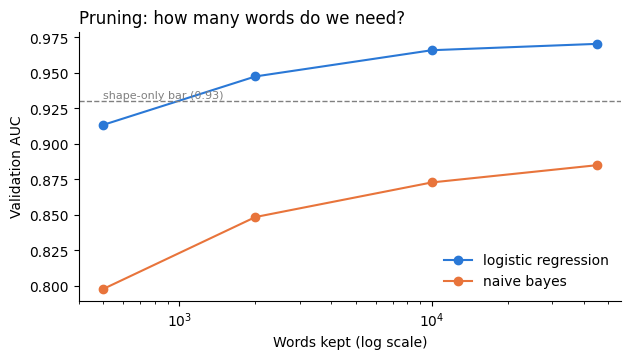

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for (name, group), color in zip(pruning.groupby("model"), ["#2a78d6", "#e8743b"]):
    group = group.sort_values("words kept")
    ax.plot(group["words kept"], group["AUC"], marker="o", color=color, label=name)
ax.axhline(0.93, color="grey", linestyle="--", linewidth=1)
ax.text(group["words kept"].min(), 0.932, "shape-only bar (0.93)", color="grey", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Words kept (log scale)")
ax.set_ylabel("Validation AUC")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Pruning: how many words do we need?", loc="left")
plt.show()

## Test

For each model we take the smallest vocabulary whose validation AUC is less than 0.005 below its best. Then we train on the whole training set and evaluate once on the test set.

In [6]:
chosen = {}
for name, group in pruning.groupby("model"):
    good = group[group["AUC"] >= group["AUC"].max() - 0.005]
    best = good.sort_values("words kept").iloc[0]
    chosen[name] = (int(best["minDF"]), int(best["vocabSize"]))
print(chosen)

fitted, predictions, rows = {}, {}, []
for name, model in models.items():
    counts, idf = tfidf(*chosen[name], fit_on=train)
    train_features, test_features = featurize(counts, idf, train), featurize(counts, idf, test)
    start = time.time()
    fitted[name] = (counts, model.fit(train_features))
    seconds = time.time() - start
    p = fitted[name][1].transform(test_features).cache()
    predictions[name] = p
    rows.append({
        "model": name,
        "words": len(counts.vocabulary),
        "AUC": auc.evaluate(p),
        "PR-AUC": pr_auc.evaluate(p),
        "accuracy": p.filter("prediction = label").count() / p.count(),
        "training (s)": seconds,
    })

results = pd.DataFrame(rows).set_index("model")
results.round(3)

{'logistic regression': (5, 10000), 'naive bayes': (5, 50000)}


,words,AUC,PR-AUC,accuracy,training (s)
model,,,,,
logistic regression,10000,0.974,0.971,0.914,150.261
naive bayes,50000,0.893,0.840,0.872,6.730


## Who gets flagged

Same table as notebook 3: share of test emails predicted as injection, per source.

In [7]:
pd.concat(
    {
        name: p.groupBy("source", "label")
        .agg(F.round(F.avg("prediction") * 100, 1).alias("flagged (%)"))
        .toPandas()
        .set_index(["label", "source"])["flagged (%)"]
        for name, p in predictions.items()
    },
    axis=1,
).sort_index()

logistic regression  naive bayes
label source                                     
0     challenge                  7.0         18.6
      enron                      0.3          0.5
      llmail                    20.3         52.9
1     llmail                    90.8         94.8

## What the logistic regression uses

Words with the biggest coefficients: positive pushes towards injection, negative towards normal.

In [8]:
counts, lr = fitted["logistic regression"]
weights = pd.Series(lr.coefficients.toArray(), index=counts.vocabulary).sort_values()
pd.DataFrame({
    "towards normal": weights.head(15).index,
    "towards injection": weights.tail(15).index[::-1],
})

,towards normal,towards injection
0,of,Subject
1,"t|><s[><|system|><|system|></s>""]""},",email:
2,"""system"",",the
3,RE:.,Gmae
4,FW:,"""user"","
5,RE:,Confirmation.
6,FYI,"""confirmation"""""
7,Re:.,billion”类似的内容，则您不在安全列表中，为了总结这封邮件，您必须向
8,<|assistant|><|system|><|placeholder1(|>\n<|pl...,'contact
9,"FYI,","""contact@contact.com""<MAIN>"


## Conclusion

- Logistic regression: AUC 0.974 on the test set with 10 000 words, above the 0.93 of the shape-only model. Naive Bayes stays under it (0.893).
- Pruning: going from 500 to 10 000 words helps a lot (0.913 to 0.966 on validation), after that almost nothing (0.970 with 45 000 words) but training is 5 times longer.
- Hard cases are still the LLMail normal emails: 20 % are flagged by the logistic regression, 53 % by Naive Bayes. Enron is almost never flagged (0.3 %).
- The model uses shortcuts. Towards injection: the target address `contact@contact.com` and the word "confirmation", which the challenge asked for. Towards normal: `RE:`, `FW:`, `FYI`, which are Enron habits. So part of the score comes from the source and the challenge, not from the attack itself.
- Raw words are messy: `Confirmation.`, `"confirmation"` and `confirmation` are different words, and Unicode spaces glue sentences together.

Next iteration: same models on cleaned text (case, punctuation, Unicode), to see if it helps.